In [2]:
%pip install -q xgboost

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import joblib

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# 1.Load dataset
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [8]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
print("\nColumn information:")
df.info()



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [10]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [11]:
print("\nTarget distribution:")
print(df["Churn"].value_counts())


Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Clean the data

In [12]:
# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check target labels
print(df["Churn"].value_counts())

Missing TotalCharges: 11
Duplicate rows: 0
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Performing basic EDA

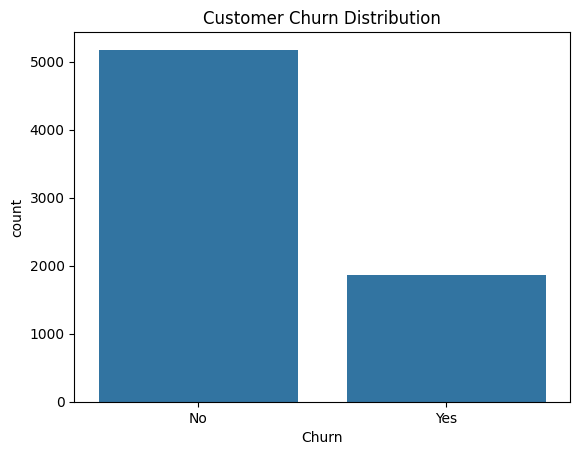

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [13]:
#Understand the churn distribution
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

print(df["Churn"].value_counts(normalize=True) * 100)

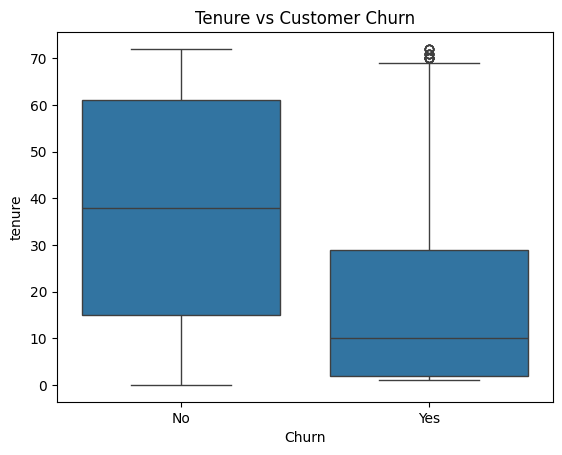

In [14]:
# Investigate tenure and churn
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Customer Churn")
plt.show()

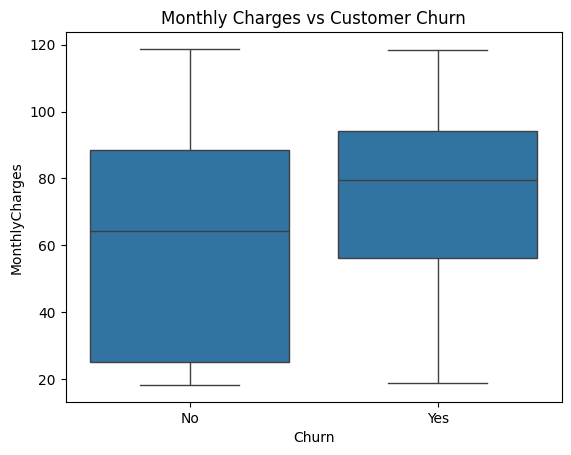

In [15]:
# Investigate monthly charges
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.show()

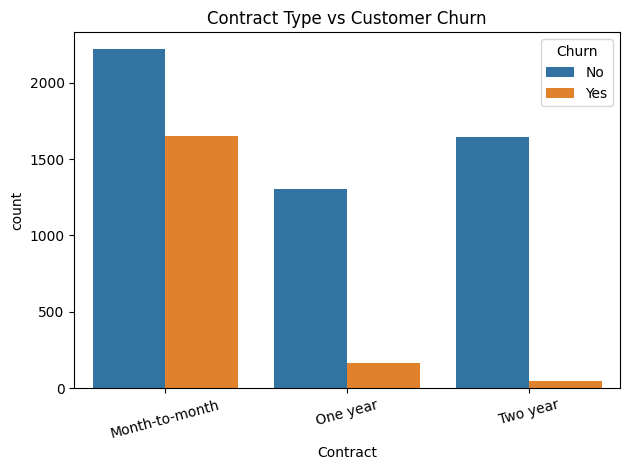

In [16]:
# Investigate contract type
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Contract Type vs Customer Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Separate features and target

In [17]:
# Remove customerID because it is an identifier,
# not a useful customer-behavior feature for this model.
X = df.drop(columns=["Churn", "customerID"])

# Target variable
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (7043, 19)
Target shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


Split the data into training and testing sets

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


Preprocess the features

In [19]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Now creating the preprocessing pipelines

In [20]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Train the Random Forest model

In [21]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Train the XGBoost model

In [22]:
# Calculate the class imbalance using training labels only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=negative_count / positive_count,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


Evaluate and compare both models

In [23]:
# Generate predictions on the same held-out test set
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)

# Positive-class probabilities for ROC-AUC
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]


def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


results = pd.DataFrame([
    evaluate_model(
        "Random Forest", y_test, rf_predictions, rf_probabilities
    ),
    evaluate_model(
        "XGBoost", y_test, xgb_predictions, xgb_probabilities
    )
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.7814,0.6170,0.4652,0.5305,0.8224
1,XGBoost,0.7594,0.5322,0.7727,0.6303,0.8414


View the confusion matrices

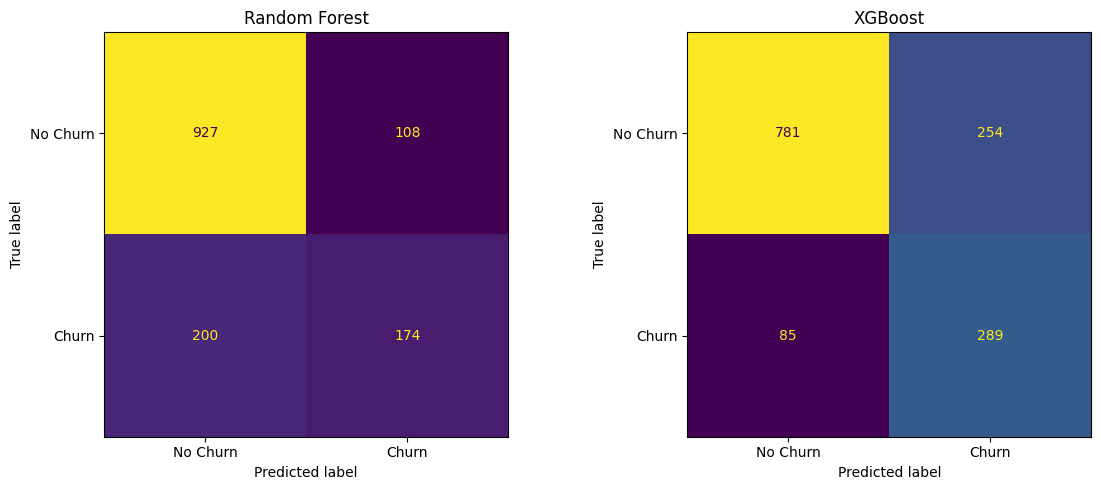

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    labels=[0, 1],
    display_labels=["No Churn", "Churn"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    labels=[0, 1],
    display_labels=["No Churn", "Churn"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

Results

In [26]:
print("RANDOM FOREST REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))



RANDOM FOREST REPORT
              precision    recall  f1-score   support

    No Churn       0.82      0.90      0.86      1035
       Churn       0.62      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



In [27]:
print("\nXGBOOST REPORT")
print(classification_report(
    y_test,
    xgb_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))


XGBOOST REPORT
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



Save both trained models

In [28]:
joblib.dump(rf_model, "random_forest_churn.pkl")
joblib.dump(xgb_model, "xgboost_churn.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [29]:
rf_model = joblib.load("random_forest_churn.pkl")
xgb_model = joblib.load("xgboost_churn.pkl")

Predict churn for a new customer

In [30]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.50,
    "TotalCharges": 427.50
}])

# Make predictions
rf_prediction = rf_model.predict(new_customer)[0]
xgb_prediction = xgb_model.predict(new_customer)[0]

# Get churn probabilities
rf_probability = rf_model.predict_proba(new_customer)[0, 1]
xgb_probability = xgb_model.predict_proba(new_customer)[0, 1]

print("Random Forest:")
print("Prediction:", "Churn" if rf_prediction == 1 else "No Churn")
print(f"Churn probability: {rf_probability:.2%}")

print("\nXGBoost:")
print("Prediction:", "Churn" if xgb_prediction == 1 else "No Churn")
print(f"Churn probability: {xgb_probability:.2%}")

Random Forest:
Prediction: Churn
Churn probability: 69.33%

XGBoost:
Prediction: Churn
Churn probability: 87.79%
